# Factor Models and Performance Attribution: Is the Fund Manager Really Skilled?

**Goal.** A fund beat its benchmark. Was it skill (alpha), or exposure to factors an
investor could buy cheaply (value, size, momentum, quality)? This is the question fund
selectors, consultants and sales teams must answer, and the one clients ask.

1. **Returns-based analysis**: regress fund returns on factor returns, with Newey-West
   standard errors, to separate alpha from factor betas.
2. **Style drift**: rolling exposures reveal a manager changing strategy.
3. **Holdings-based attribution (Brinson-Fachler)**: did the outperformance come from
   sector bets or from stock picking? Effects linked over 12 months with Carino's method.

Factor and fund returns are simulated (15 years, monthly) with known exposures, so we can
check that the methods find the truth.

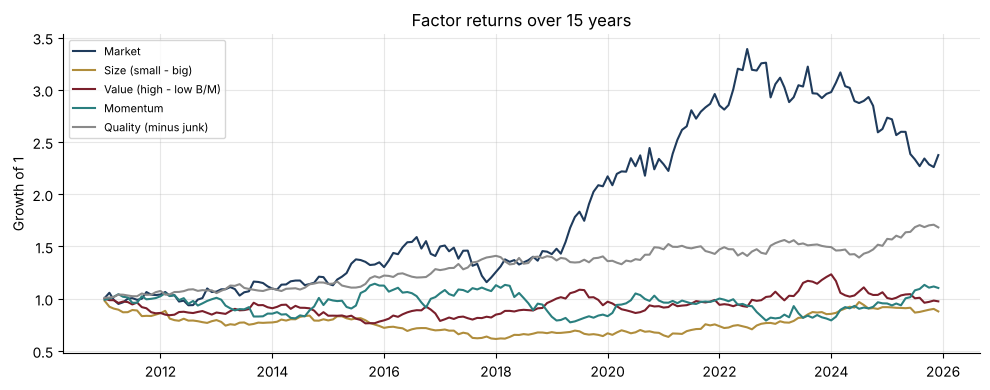

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("factors.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/18-factor-models-attribution")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from factors import (FACTORS, simulate_factors, simulate_fund, factor_regression, rolling_betas, return_decomposition,
                     brinson_fachler, carino_link, performance_stats)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
factors = simulate_factors(180, seed=7)
names = {"MKT": "Market", "SMB": "Size (small - big)", "HML": "Value (high - low B/M)", "MOM": "Momentum", "QMJ": "Quality (minus junk)"}
fig, ax = plt.subplots(figsize=(10, 4))
for f, c in zip(FACTORS, [NAVY, GOLD, BORDEAUX, TEAL, GREY]):
    ax.plot(factors.index.to_timestamp(), (1 + factors[f]).cumprod(), color=c, lw=1.5, label=names[f])
ax.set(ylabel="Growth of 1", title="Factor returns over 15 years"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/factors.png", dpi=150); plt.show()

## 1. Three funds, three stories

| Fund | Marketing pitch | True construction (unknown to the analyst) |
|---|---|---|
| A, "European Value" | beats the index | market + value tilt, **no alpha** |
| B, "Quality Growth" | stock-picking skill | quality and momentum tilts + **2% alpha** |
| C, "Small Cap Opportunities" | small-cap specialist | small-cap tilt, −1% alpha (fees), **drifts into value** after year 10 |

In [2]:
funds = {
    "A - European Value": simulate_fund(factors, [0.95, -0.10, 0.55, -0.05, 0.10], alpha_annual=0.0, idio_vol_annual=0.025, seed=11),
    "B - Quality Growth": simulate_fund(factors, [0.90, 0.00, -0.30, 0.30, 0.50], alpha_annual=0.02, idio_vol_annual=0.03, seed=12),
    "C - Small Cap Opp.": simulate_fund(factors, [1.10, 0.70, 0.00, 0.00, -0.10], alpha_annual=-0.01, idio_vol_annual=0.03, seed=13,
                                        drift=(120, [1.05, 0.60, 0.50, 0.00, -0.10])),
}
rows = {}
for name, r in funds.items():
    reg = factor_regression(r, factors, lags=3)
    rows[name] = {"Alpha (% p.a.)": reg.loc["alpha (monthly)", "coef"] * 1200, "Alpha t-stat (HAC)": reg.loc["alpha (monthly)", "t-stat (HAC)"],
                  **{f: reg.loc[f, "coef"] for f in FACTORS}, "R²": reg.attrs["r2"],
                  "Excess return vs market (% p.a.)": (r.mean() - factors["MKT"].mean()) * 1200}
pd.DataFrame(rows).T.round(2)

,Alpha (% p.a.),Alpha t-stat (HAC),MKT,SMB,HML,MOM,QMJ,R²,Excess return vs market (% p.a.)
A - European Value,0.74,1.07,0.94,-0.11,0.52,-0.05,0.04,0.97,0.64
B - Quality Growth,2.01,2.17,0.89,-0.04,-0.32,0.30,0.49,0.95,3.48
C - Small Cap Opp.,0.60,0.54,1.09,0.67,0.18,0.02,-0.15,0.96,0.39


**Reading the regressions.**
- **Fund A** beats the market by about 0.6% a year, but its alpha is not significant
  (t ≈ 1.1). With a value tilt of 0.5, its record is consistent with no skill at all.
- **Fund B** has a significant alpha (t > 2) on top of its quality and momentum tilts: the
  only manager in the sample who earns active fees.
- **Fund C**'s true alpha is −1%, yet the estimate is slightly positive and insignificant:
  15 years of monthly data cannot separate a 1% fee drag from noise. Its value beta (about
  0.2) is neither 0 nor 0.5, because a full-sample regression averages two strategies
  (section 3).

Newey-West standard errors matter: fund returns are autocorrelated (stale prices, smoothing),
and plain OLS standard errors would overstate the significance of alpha.

## 2. Where did each fund's return come from?

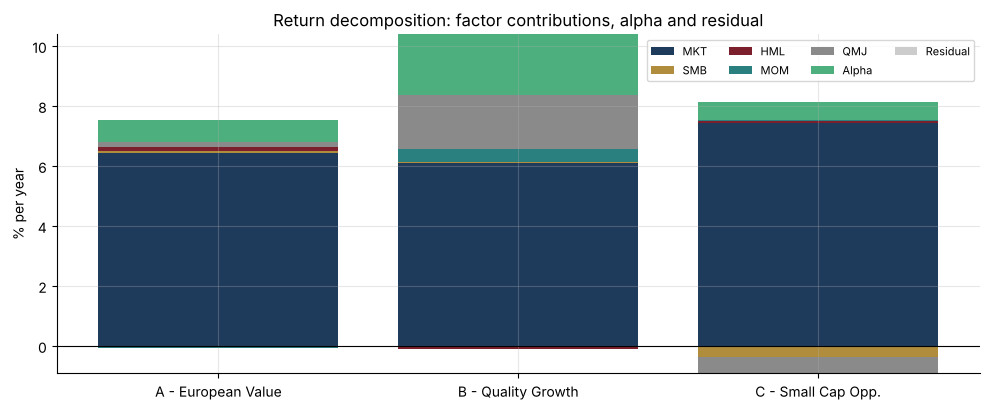

,MKT,SMB,HML,MOM,QMJ,Alpha,Residual
A - European Value,6.44,0.06,0.14,-0.07,0.16,0.74,0.0
B - Quality Growth,6.10,0.02,-0.09,0.45,1.81,2.01,0.0
C - Small Cap Opp.,7.45,-0.36,0.05,0.03,-0.55,0.60,0.0


In [3]:
dec = pd.DataFrame({name: return_decomposition(r, factors, factor_regression(r, factors)["coef"].values) * 100
                    for name, r in funds.items()}).T
fig, ax = plt.subplots(figsize=(10, 4.2))
bottom_pos, bottom_neg = np.zeros(len(dec)), np.zeros(len(dec))
for col, c in zip(dec.columns, [NAVY, GOLD, BORDEAUX, TEAL, GREY, "#4caf7d", "#cccccc"]):
    vals = dec[col].values
    ax.bar(dec.index, np.where(vals > 0, vals, 0), bottom=bottom_pos, color=c, label=col)
    ax.bar(dec.index, np.where(vals < 0, vals, 0), bottom=bottom_neg, color=c)
    bottom_pos += np.where(vals > 0, vals, 0); bottom_neg += np.where(vals < 0, vals, 0)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("% per year"); ax.legend(ncol=4, fontsize=8)
ax.set_title("Return decomposition: factor contributions, alpha and residual")
plt.tight_layout(); plt.savefig("images/decomposition.png", dpi=150); plt.show()
dec.round(2)

## 3. Style drift

A 36-month rolling regression of Fund C shows its value exposure jumping from 0 to about 0.5
after year 10: the "small-cap specialist" has quietly become a small-cap **value** fund.
For a fund selector this is a red flag: the fund no longer fills the slot it was bought for.

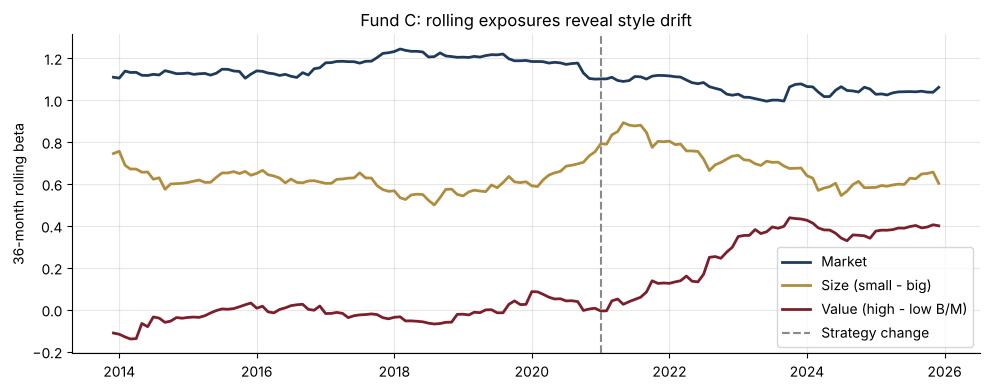

In [4]:
rb = rolling_betas(funds["C - Small Cap Opp."], factors, 36)
fig, ax = plt.subplots(figsize=(10, 4))
for f, c in zip(["MKT", "SMB", "HML"], [NAVY, GOLD, BORDEAUX]):
    ax.plot(rb.index.to_timestamp(), rb[f], color=c, lw=2, label=names[f])
ax.axvline(factors.index[120].to_timestamp(), color=GREY, ls="--", label="Strategy change")
ax.set(ylabel="36-month rolling beta", title="Fund C: rolling exposures reveal style drift"); ax.legend()
plt.tight_layout(); plt.savefig("images/style_drift.png", dpi=150); plt.show()

## 4. Brinson-Fachler attribution: sector bets or stock picking?

An equity fund against its benchmark over 12 months, by sector. Each month:

- **Allocation** $= (w_p - w_b)(r_b - R_b)$: reward for overweighting sectors that beat the benchmark
- **Selection** $= w_b(r_p - r_b)$: reward for picking better stocks within each sector
- **Interaction** $= (w_p - w_b)(r_p - r_b)$

Monthly effects do not add up over time because returns compound; **Carino linking**
rescales them so the 12-month effects add up exactly to the compounded active return.

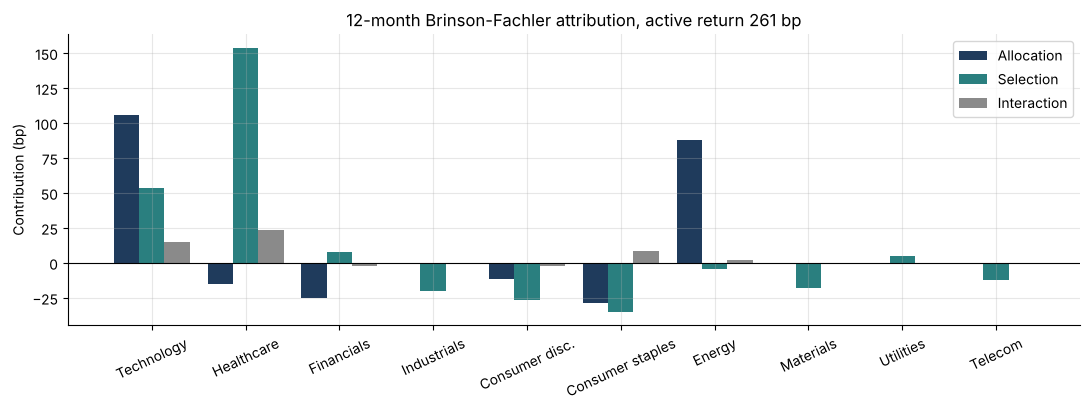

,bp
allocation,113.3
selection,102.7
interaction,44.8
Total (linked),260.8
Compounded active return,260.8


In [5]:
sectors = ["Technology", "Healthcare", "Financials", "Industrials", "Consumer disc.", "Consumer staples",
           "Energy", "Materials", "Utilities", "Telecom"]
rng = np.random.default_rng(5)
wb = np.array([0.22, 0.13, 0.15, 0.12, 0.11, 0.08, 0.06, 0.05, 0.04, 0.04])
wp = wb + np.array([0.06, 0.02, -0.04, 0.0, 0.01, -0.02, -0.03, 0.0, 0.0, 0.0])    # overweight tech, underweight energy
effects, Rp, Rb = [], [], []
for m in range(12):
    rb_s = rng.normal(0.008, 0.045, 10) + np.array([0.006, 0, 0, 0, 0, 0, -0.004, 0, 0, 0])
    rp_s = rb_s + rng.normal(0, 0.01, 10) + np.array([0, 0.008, 0, 0, 0, 0, 0, 0, 0, 0])   # stock picking in healthcare
    effects.append(brinson_fachler(wp, wb, rp_s, rb_s)); Rp.append(wp @ rp_s); Rb.append(wb @ rb_s)
linked = carino_link(effects, Rp, Rb)
linked.index = sectors
total_active = np.prod(1 + np.array(Rp)) - np.prod(1 + np.array(Rb))
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(10)
for k, (col, c) in enumerate([("allocation", NAVY), ("selection", TEAL), ("interaction", GREY)]):
    ax.bar(x + (k - 1) * 0.27, linked[col] * 1e4, width=0.27, color=c, label=col.capitalize())
ax.set_xticks(x, sectors, rotation=25); ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("Contribution (bp)")
ax.set_title(f"12-month Brinson-Fachler attribution, active return {total_active * 1e4:.0f} bp"); ax.legend()
plt.tight_layout(); plt.savefig("images/brinson.png", dpi=150); plt.show()
summary = linked.sum().mul(1e4).round(1)
summary["Total (linked)"] = round(linked.values.sum() * 1e4, 1)
summary["Compounded active return"] = round(total_active * 1e4, 1)
summary.to_frame("bp")

The linked effects add up exactly to the compounded active return (the test suite checks
it). The attribution separates the manager's two decisions: the technology overweight
(allocation) and the stock picking in healthcare (selection).

## 5. Performance statistics against the market

In [6]:
pd.DataFrame({name: performance_stats(r + 0.002, factors["MKT"] + 0.002, rf_monthly=0.002) for name, r in funds.items()}).T.style.format("{:.2f}")

,Annual return,Annual vol,Sharpe,Sortino,Max drawdown,Tracking error,Information ratio
A - European Value,0.09,0.15,0.50,0.81,-0.28,0.06,0.11
B - Quality Growth,0.13,0.13,0.79,1.38,-0.17,0.09,0.40
C - Small Cap Opp.,0.08,0.19,0.38,0.57,-0.40,0.08,0.05


## Conclusions
- Returns-based regressions separate factor exposure from alpha: only one of the three
  funds shows significant skill once value, size, momentum and quality are accounted for,
  and even 15 years of data leave large uncertainty on alpha.
- Rolling regressions catch style drift that a full-sample regression hides.
- Brinson-Fachler with Carino linking explains active return by decision, and adds up exactly.
- **Next steps:** holdings-based factor exposures (Barra-style risk model), fixed-income
  attribution (carry, curve, spread), and a factor-based fund-selection screen.